# PHI4005 Assignment 2 — XY EarlyAlert Drift Audit
**Name: Damis gabriel Manfouo**  
**Student #: 041204270**  
 

## 0. Setup and data loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker import PercentFormatter
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from numpy import shape
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score, precision_score, roc_auc_score)



In [2]:
# import dataset
fall23_data = pd.read_csv("../data/XY_fall2023_cohort.csv") 
fall25_data = pd.read_csv("../data/XY_fall2025_cohort.csv")


## Part 1 — Baseline model (Fall 2023 cohort)
### 1.1 Explore the data


In [3]:
fall23_data.shape

(4200, 16)

In [4]:
fall23_data.dtypes

student_id                       str
intake_term                      str
program                          str
delivery_mode                    str
age                            int64
international                  int64
first_generation               int64
financial_aid                  int64
hs_average                   float64
credits_attempted              int64
work_hours_week                int64
commute_minutes                int64
lms_logins_first4wks           int64
assignments_submitted_pct      int64
outstanding_balance            int64
did_not_return                 int64
dtype: object

In [5]:
fall23_data.describe()

,age,international,first_generation,financial_aid,hs_average,credits_attempted,work_hours_week,commute_minutes,lms_logins_first4wks,assignments_submitted_pct,outstanding_balance,did_not_return
count,4200.000000,4200.000000,4200.000000,4200.000000,4200.00000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000
mean,21.570952,0.311667,0.331429,0.483333,76.10031,14.207143,13.362143,27.802857,28.757857,77.372857,374.895238,0.240714
std,4.976220,0.463230,0.470783,0.499782,7.90715,2.644436,9.801048,22.004117,12.035143,14.473503,804.667640,0.427568
min,17.000000,0.000000,0.000000,0.000000,55.00000,9.000000,0.000000,0.000000,4.000000,8.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,70.70000,12.000000,6.000000,12.000000,20.000000,68.000000,0.000000,0.000000
50%,20.000000,0.000000,0.000000,0.000000,75.90000,15.000000,11.000000,24.000000,27.000000,78.000000,0.000000,0.000000
75%,21.000000,1.000000,1.000000,1.000000,81.40000,15.000000,18.000000,39.000000,35.000000,88.000000,310.000000,0.000000
max,51.000000,1.000000,1.000000,1.000000,99.00000,18.000000,45.000000,185.000000,103.000000,100.000000,6440.000000,1.000000


In [6]:
fall23_data.head()

,student_id,intake_term,program,delivery_mode,age,international,first_generation,financial_aid,hs_average,credits_attempted,work_hours_week,commute_minutes,lms_logins_first4wks,assignments_submitted_pct,outstanding_balance,did_not_return
0,NB23-00001,Fall 2023,Skilled Trades,in_person,22,1,0,1,71.6,9,15,64,32,79,0,0
1,NB23-00002,Fall 2023,Health Sciences,in_person,21,0,0,0,65.4,15,13,17,32,76,560,0
2,NB23-00003,Fall 2023,Computer Programming,in_person,21,0,0,1,71.5,15,10,27,20,84,0,1
3,NB23-00004,Fall 2023,Business,in_person,18,0,0,0,76.0,18,4,10,37,100,0,0
4,NB23-00005,Fall 2023,Hospitality,in_person,35,0,0,0,78.3,15,19,37,16,77,0,0


In [7]:
fall23_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 4200 non-null   str    
 1   intake_term                4200 non-null   str    
 2   program                    4200 non-null   str    
 3   delivery_mode              4200 non-null   str    
 4   age                        4200 non-null   int64  
 5   international              4200 non-null   int64  
 6   first_generation           4200 non-null   int64  
 7   financial_aid              4200 non-null   int64  
 8   hs_average                 4200 non-null   float64
 9   credits_attempted          4200 non-null   int64  
 10  work_hours_week            4200 non-null   int64  
 11  commute_minutes            4200 non-null   int64  
 12  lms_logins_first4wks       4200 non-null   int64  
 13  assignments_submitted_pct  4200 non-null   int64  
 14  out

In [8]:
# missing values
# Missing values
missing = pd.DataFrame({
    "Missing Count": fall23_data.isna().sum(),
    "Missing %": fall23_data.isna().mean() * 100
})
display(missing)


,Missing Count,Missing %
student_id,0,0.0
intake_term,0,0.0
program,0,0.0
delivery_mode,0,0.0
age,0,0.0
international,0,0.0
first_generation,0,0.0
financial_aid,0,0.0
hs_average,0,0.0
credits_attempted,0,0.0


In [9]:
# Duplicate values
print("Duplicate rows")
print("Duplicates:", fall23_data.duplicated().sum())


Duplicate rows
Duplicates: 0


did_not_return
0    3189
1    1011
Name: count, dtype: int64


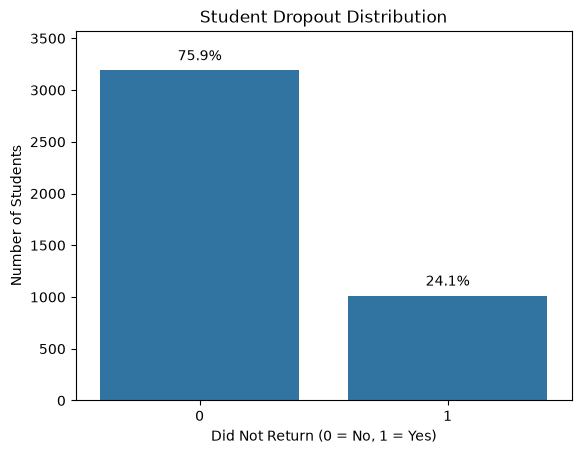

Dropout Rate: 24.07%


In [10]:
# target analysis (did_not_return)
print(fall23_data['did_not_return'].value_counts())

ax = sns.countplot(
    data=fall23_data,
    x="did_not_return",
    order=[0, 1]
)

total = len(fall23_data)

for bar in ax.patches:
    count = bar.get_height()
    percentage = count / total * 100

    ax.annotate(
        f"{percentage:.1f}%",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.set_ylim(0, max(p.get_height() for p in ax.patches) * 1.12)

plt.title("Student Dropout Distribution")
plt.xlabel("Did Not Return (0 = No, 1 = Yes)")
plt.ylabel("Number of Students")
plt.show()

dropout_rate = fall23_data['did_not_return'].mean() * 100
print(f"Dropout Rate: {dropout_rate:.2f}%")


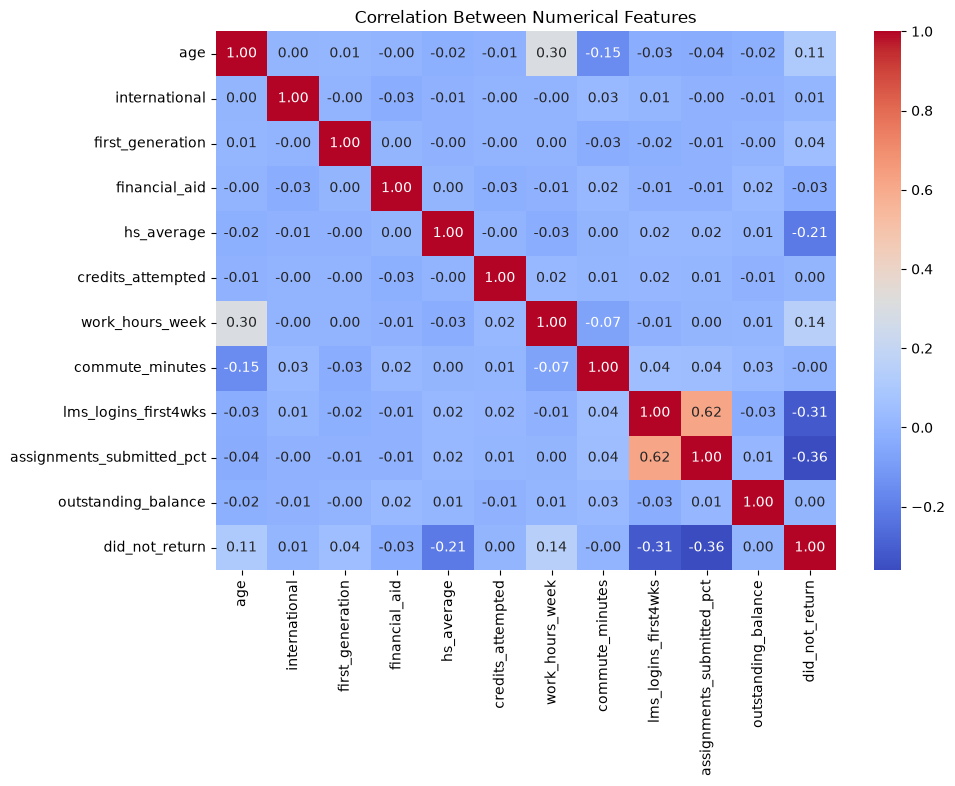

In [11]:
# correlation between numeric features
numeric_features = fall23_data.select_dtypes(include="number").columns
matrix = fall23_data[numeric_features].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(
    matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Numerical Features")
plt.show()

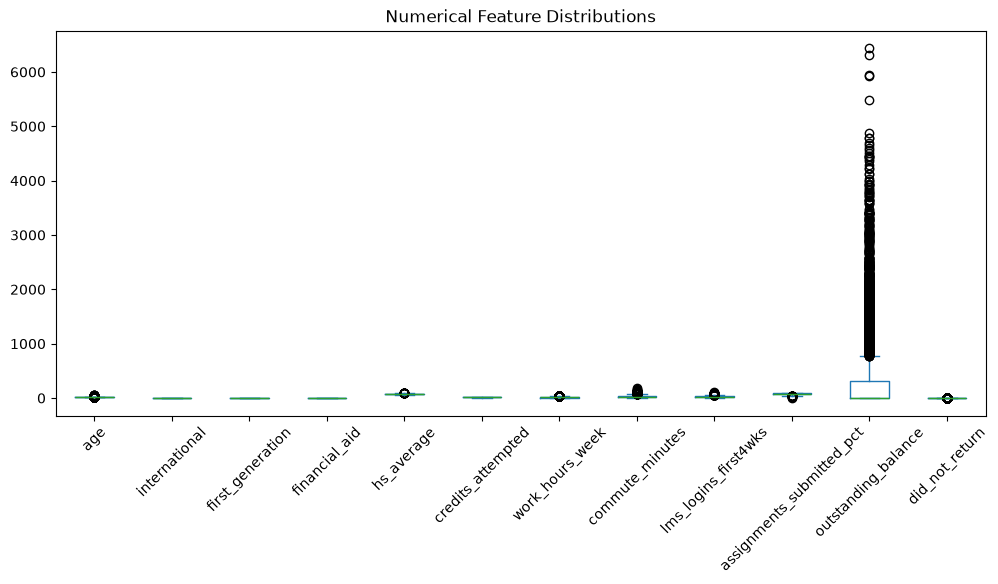

In [12]:
# outlier detection for numeric features

fall23_data[numeric_features].plot(
    kind="box",
    figsize=(12, 5),
    rot=45
)

plt.title("Numerical Feature Distributions")
plt.show()


### 1.2 Train your model (25% held-out test set)


In [ ]:

dropped_attributes = ["student_id", "intake_term", "did_not_return"]
features = fall23_data.drop(columns=dropped_attributes)

categorical_features = ["program", "delivery_mode"]
binary_features = ["international", "first_generation", "financial_aid"]
#remove did_not_return from numerical_features
numerical_features = [col for col in numeric_features if col not in ["did_not_return", "international", "first_generation", "financial_aid"]]

# define features and target variable
target = fall23_data["did_not_return"]

# splitting the dataset into training and testing sets

features_train, features_test, target_train, target_test = train_test_split(
    features,
    target,
    test_size=0.25,
    random_state=42,
    stratify=target
)


features_train.shape, target_train.shape, features_test.shape, target_test.shape

((3150, 13), (3150,), (1050, 13), (1050,))

In [14]:
# Data preprocessing pipelines
preprocessor = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features),

    ("binary", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ]), binary_features),

    ("numerical", Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", StandardScaler())
    ]), numerical_features)
])

In [15]:
# Train the model

training_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model = training_model.fit(features_train, target_train)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['program','delivery_mode','age',...,'lms_logins_first4wks', 'assignments_submitted_pct','outstanding_balance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('binary', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default o

In [16]:
# Test the model on the test set
test_predictions_proba = model.predict_proba(features_test)[:,1]



### 1.3 Metrics at the 0.30 EarlyAlert threshold
*Markdown: justify your model choice in 2–3 sentences.*

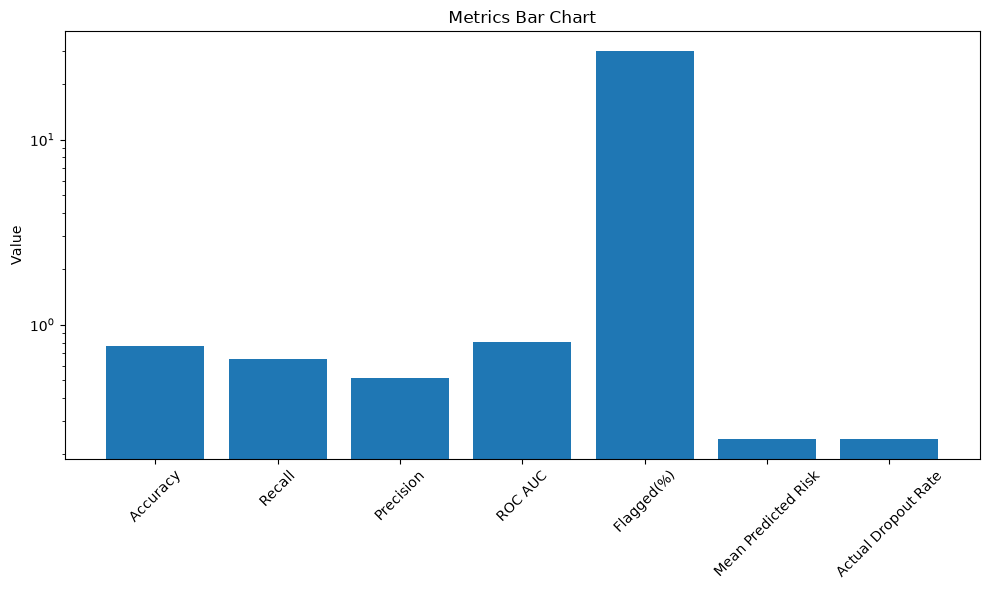

,Metric,Value
0,Accuracy,0.769524
1,Recall,0.648221
2,Precision,0.517350
3,ROC AUC,0.804311
4,Flagged(%),30.190476
5,Mean Predicted Risk,0.239263
6,Actual Dropout Rate,0.240952


In [17]:
predicted_labels = (test_predictions_proba>= 0.3).astype(int)

metrics_23 = pd.Series({
    "Accuracy": accuracy_score(target_test, predicted_labels),
    "Recall": recall_score(target_test, predicted_labels),
    "Precision": precision_score(target_test, predicted_labels),
    "ROC AUC": roc_auc_score(target_test, test_predictions_proba),
    "Flagged(%)": predicted_labels.mean()*100,
    "Mean Predicted Risk": test_predictions_proba.mean(),
    "Actual Dropout Rate": target_test.mean()    
})

metrics_df = pd.DataFrame(metrics_23.items(), columns=["Metric", "Value"])



plt.figure(figsize=(10, 6))
bars = plt.bar(metrics_df["Metric"], metrics_df["Value"])
plt.xticks(rotation=45)
plt.ylabel("Value")
plt.title("Metrics Bar Chart")
plt.yscale("log")
plt.tight_layout()
plt.show()

metrics_df.head(10)

## Part 2 — Performance after deployment (Fall 2025 cohort)
### 2.1 Overall metrics (same as 1.3)


<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 3900 non-null   str    
 1   intake_term                3900 non-null   str    
 2   program                    3900 non-null   str    
 3   delivery_mode              3900 non-null   str    
 4   age                        3900 non-null   int64  
 5   international              3900 non-null   int64  
 6   first_generation           3900 non-null   int64  
 7   financial_aid              3900 non-null   int64  
 8   hs_average                 3900 non-null   float64
 9   credits_attempted          3900 non-null   int64  
 10  work_hours_week            3900 non-null   int64  
 11  commute_minutes            3900 non-null   int64  
 12  lms_logins_first4wks       3900 non-null   int64  
 13  assignments_submitted_pct  3900 non-null   int64  
 14  out

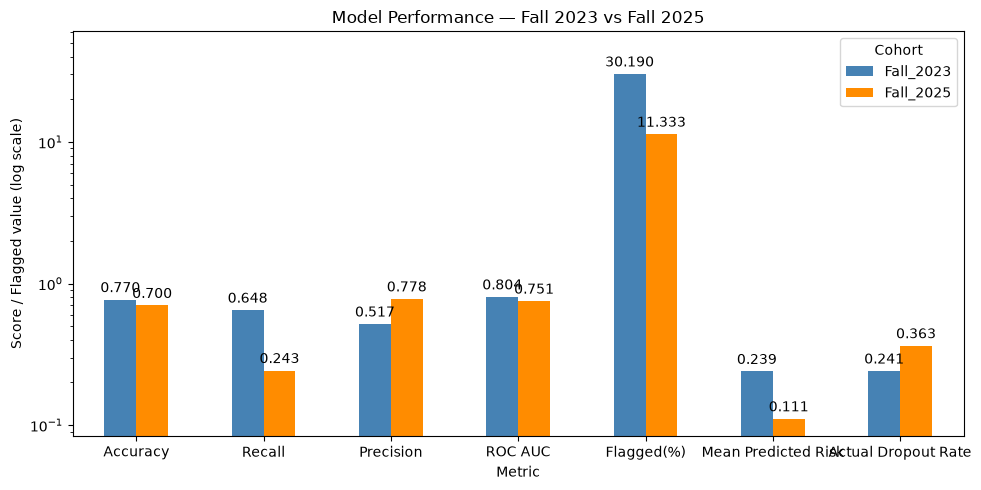

In [18]:
fall25_data.describe()
fall25_data.info()


features_25 = fall25_data.drop(columns=dropped_attributes)
target_25 = fall25_data["did_not_return"]

predictions_proba_25 = model.predict_proba(features_25)[:, 1]
predicted_labels_25 = (predictions_proba_25 >= 0.3).astype(int)

metrics_25 = pd.Series({
   "Accuracy": accuracy_score(target_25, predicted_labels_25),
   "Recall": recall_score(target_25, predicted_labels_25),
   "Precision": precision_score(target_25, predicted_labels_25),
   "ROC AUC": roc_auc_score(target_25, predictions_proba_25),
   "Flagged(%)":  predicted_labels_25.mean()*100,
   "Mean Predicted Risk": predictions_proba_25.mean(),
   "Actual Dropout Rate": target_25.mean()
})

metrics_23_25 = pd.DataFrame({
    "Fall_2023": metrics_23,
    "Fall_2025": metrics_25
})

## Build a bar chart to compare the metrics between Fall 2023 and Fall 2025
ax = metrics_23_25.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
    rot=0
)

ax.set_yscale("log")
ax.set_ylim(top=metrics_23_25.max().max() * 2)

ax.set_title("Model Performance — Fall 2023 vs Fall 2025")
ax.set_xlabel("Metric")
ax.set_ylabel("Score / Flagged value (log scale)")
ax.legend(title="Cohort")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()




### 2.2 Subgroup analysis (at least three groups)


In [31]:
fall25_data.head(10)
fall25_data.dtypes

student_id                       str
intake_term                      str
program                          str
delivery_mode                    str
age                            int64
international                  int64
first_generation               int64
financial_aid                  int64
hs_average                   float64
credits_attempted              int64
work_hours_week                int64
commute_minutes                int64
lms_logins_first4wks           int64
assignments_submitted_pct      int64
outstanding_balance            int64
did_not_return                 int64
dtype: object

In [ ]:

def generate_metrics(features, target):
    proba = model.predict_proba(features)[:, 1]
    labels = (proba >= 0.3).astype(int)
    metrics = pd.Series({
        "Recall": recall_score(target, labels),
        "Mean Predicted Risk": proba.mean(),
        "Actual Dropout Rate": target.mean()
    })
    return metrics

# metrics for delivery mode = in person
dm_in_pers = fall25_data[fall25_data['delivery_mode'] == "in_person"]
dm_in_pers_features = dm_in_pers.drop(columns=dropped_attributes)
dm_in_pers_target = dm_in_pers["did_not_return"]
dm_in_person_metrics = generate_metrics(dm_in_pers_features, dm_in_pers_target)

# metrics for delivery mode = hybrid
dm_hybrid = fall25_data[fall25_data['delivery_mode'] == "hybrid"]
dm_hybrid_features = dm_hybrid.drop(columns=dropped_attributes)
dm_hybrid_target = dm_hybrid["did_not_return"]
dm_hybrid_metrics = generate_metrics(dm_hybrid_features, dm_hybrid_target)

# metrics for delivery mode = online
dm_online = fall25_data[fall25_data['delivery_mode'] == "online"]
dm_online_features = dm_online.drop(columns=dropped_attributes)
dm_online_target = dm_online["did_not_return"]
dm_online_metrics = generate_metrics(dm_online_features, dm_online_target)

# metrics for domestic student(0)
inter_domestic = fall25_data[fall25_data['international'] == 0]
inter_domestic_features = inter_domestic.drop(columns=dropped_attributes)
inter_domestic_target = inter_domestic["did_not_return"]
inter_domestic_metrics = generate_metrics(inter_domestic_features, inter_domestic_target)

# metrics for international student(1)
inter_international = fall25_data[fall25_data['international'] == 1]
inter_international_features = inter_international.drop(columns=dropped_attributes)
inter_international_target = inter_international["did_not_return"]
inter_international_metrics = generate_metrics(inter_international_features, inter_international_target)

# metrics for age < 25
age_less_25 = fall25_data[fall25_data['age'] < 25]
age_less_25_features = age_less_25.drop(columns=dropped_attributes)
age_less_25_target = age_less_25["did_not_return"]
age_less_25_metrics = generate_metrics(age_less_25_features, age_less_25_target)

# metrics for age >= 25
age_more_25 = fall25_data[fall25_data['age'] >= 25]
age_more_25_features = age_more_25.drop(columns=dropped_attributes)
age_more_25_target = age_more_25["did_not_return"]
age_more_25_metrics = generate_metrics(age_more_25_features, age_more_25_target)


grouped_metrics = pd.DataFrame({
    "In person Delivery": dm_in_person_metrics, 
    "Hyrid Delivery": dm_hybrid_metrics,
    "Online Delivery": dm_online_metrics,
    "Domestic Students": inter_domestic_metrics,
    "international Students": inter_international_metrics,
    "Age < 25": age_less_25_metrics,
    "Age >25": age_more_25_metrics
})






,In person Delivery,Hyrid Delivery,Online Delivery,Domestic Students,international Students,Age < 25,Age >25
Recall,0.186933,0.173554,0.318910,0.236470,0.277778,0.170306,0.375250
Mean Predicted Risk,0.085379,0.076973,0.162045,0.110238,0.114044,0.087273,0.164443
Actual Dropout Rate,0.318866,0.305556,0.452174,0.361312,0.375000,0.337883,0.421362


### 2.3 Missed dropouts
*Markdown: what changed, and what would the college have seen if it only tracked accuracy?*

## Part 3 — Drift detection
### 3.1 Your PSI function  + GREEN / AMBER / RED table for every feature
### 3.2 A second statistical test (KS, Wasserstein )
### 3.3 Model-based detection: domain classifier
